# Projeto Final - Machine Learning

## Previsão do Valor de Financiamento Habitacional do Programa Minha Casa Minha Vida (MCMV)

### Contexto

O Programa Minha Casa Minha Vida (MCMV) é uma das principais iniciativas de política habitacional do Brasil, voltada à ampliação do acesso à moradia por meio de mecanismos de financiamento e subsídios habitacionais.

A base utilizada neste projeto contém aproximadamente 7,8 milhões de registros de operações de financiamento habitacional e 21 variáveis. Entre as informações disponíveis estão localização geográfica, renda familiar, valor de compra do imóvel, subsídios, taxa de juros e características da operação.

### Problema

Dadas as características disponíveis das operações de financiamento habitacional, é possível estimar o valor do financiamento concedido no Programa Minha Casa Minha Vida?

Além da capacidade preditiva, o projeto busca investigar quais características disponíveis na base apresentam maior contribuição para a estimativa do valor financiado.

### Objetivo

Desenvolver e avaliar modelos de Machine Learning capazes de estimar o valor do financiamento habitacional concedido no âmbito do Programa Minha Casa Minha Vida, utilizando as características disponíveis das operações.

### Variável-alvo (Target)

A variável-alvo será:

`vlr_financiamento`

Essa variável representa o valor do financiamento habitacional e constitui a variável numérica que os modelos tentarão estimar.

### Tipo de problema

- Aprendizado supervisionado
- Regressão

O problema é caracterizado como regressão porque a variável-alvo `vlr_financiamento` é uma variável numérica contínua.

### Variáveis candidatas

A base contém informações potencialmente explicativas relacionadas a:

- localização geográfica;
- renda familiar;
- valor de compra do imóvel;
- subsídios concedidos;
- taxa de juros;
- programa habitacional;
- tipo do imóvel;
- condição de cotista;
- sistema de amortização;
- compatibilidade com faixa de renda;
- características temporais da operação.

As variáveis efetivamente utilizadas nos modelos serão definidas após a análise exploratória dos dados e a avaliação de possível vazamento de informações (data leakage).

Uma variável somente deverá ser utilizada como preditora caso sua utilização seja metodologicamente adequada ao momento em que a previsão seria realizada.

### Hipótese inicial

Parte-se da hipótese de que características econômicas, geográficas e contratuais das operações apresentam capacidade preditiva sobre o valor do financiamento.

Será investigada especialmente a relação entre `vlr_financiamento` e variáveis como renda familiar, valor de compra do imóvel, subsídios, localização e condições da operação.

Essa hipótese será avaliada empiricamente durante a análise exploratória e a modelagem, sem pressupor previamente quais variáveis deverão compor o modelo final.

### Estratégia de modelagem

Inicialmente será utilizado um modelo simples como baseline, estabelecendo uma referência mínima de desempenho.

Posteriormente, diferentes algoritmos de regressão serão treinados e comparados.

O projeto buscará avaliar não apenas o desempenho preditivo, mas também aspectos relacionados a:

- generalização do modelo;
- overfitting;
- vazamento de informações;
- pré-processamento das variáveis;
- interpretação dos resultados;
- limitações do modelo.

### Métricas de avaliação

Os modelos serão avaliados principalmente pelas seguintes métricas:

- **MAE (Mean Absolute Error):** erro absoluto médio das previsões;
- **RMSE (Root Mean Squared Error):** medida de erro que penaliza mais fortemente erros elevados;
- **R² (Coeficiente de Determinação):** proporção da variabilidade da variável-alvo explicada pelo modelo.

O MAE terá especial relevância por permitir interpretar o erro médio do modelo diretamente em reais (R$), mesma unidade da variável `vlr_financiamento`.

### Resultado esperado

Espera-se construir um fluxo completo de Machine Learning, abrangendo análise exploratória, pré-processamento, treinamento, validação e comparação de modelos de regressão.

Ao final, pretende-se identificar o desempenho dos modelos, suas principais limitações e as características das operações que mais contribuem para a previsão do valor financiado.

## 2. Fonte, Obtenção e Validação dos Dados

### Fonte dos dados

A base utilizada contém dados do Programa Minha Casa Minha Vida (MCMV), disponibilizados pelo Ministério das Cidades.

O conjunto de dados é distribuído em arquivo compactado no formato ZIP e contém registros de operações de financiamento habitacional.

### Aquisição dos dados

Para tornar o projeto reproduzível, a obtenção da base foi automatizada no próprio notebook.

O processo consiste em:

1. verificar se a base já está disponível localmente;
2. realizar o download do arquivo compactado quando necessário;
3. validar o arquivo obtido;
4. descompactar o CSV automaticamente;
5. manter os arquivos de dados fora do versionamento Git.

### Validação inicial

Antes da análise exploratória, serão verificados:

- existência e tamanho do arquivo;
- estrutura do conjunto de dados;
- quantidade de variáveis;
- nomes das colunas;
- tipos inicialmente identificados;
- capacidade de leitura adequada do CSV.

Nesta etapa não serão realizadas transformações nos dados.

In [2]:
## Obtenção e preparação da base original

""" from pathlib import Path
from urllib.request import urlretrieve
import zipfile

# URL oficial da base
URL = "https://www.cidades.gov.br/images/stories/ArquivosSNH/ArquivosZIP/mcmv_financ_analitico_20260724.zip"

# Como o notebook está em /notebooks, a raiz é um nível acima
PROJETO = Path.cwd().parent
PASTA_DADOS = PROJETO / "data"

ARQUIVO_ZIP = PASTA_DADOS / "mcmv_financ_analitico_20260724.zip"
ARQUIVO_CSV = PASTA_DADOS / "mcmv_financ_analitico_20260724.csv"

# Cria a pasta data, caso ainda não exista
PASTA_DADOS.mkdir(parents=True, exist_ok=True)

# Baixa somente se o CSV ainda não estiver disponível
if not ARQUIVO_CSV.exists():

    if not ARQUIVO_ZIP.exists():
        print("Baixando a base MCMV...")
        urlretrieve(URL, ARQUIVO_ZIP)
        print("Download concluído.")

    print("Descompactando a base...")

    with zipfile.ZipFile(ARQUIVO_ZIP, "r") as zip_ref:
        zip_ref.extractall(PASTA_DADOS)

    print("Descompactação concluída.")

else:
    print("Base já disponível localmente.")

print(f"Arquivo: {ARQUIVO_CSV}") """

' from pathlib import Path\nfrom urllib.request import urlretrieve\nimport zipfile\n\n# URL oficial da base\nURL = "https://www.cidades.gov.br/images/stories/ArquivosSNH/ArquivosZIP/mcmv_financ_analitico_20260724.zip"\n\n# Como o notebook está em /notebooks, a raiz é um nível acima\nPROJETO = Path.cwd().parent\nPASTA_DADOS = PROJETO / "data"\n\nARQUIVO_ZIP = PASTA_DADOS / "mcmv_financ_analitico_20260724.zip"\nARQUIVO_CSV = PASTA_DADOS / "mcmv_financ_analitico_20260724.csv"\n\n# Cria a pasta data, caso ainda não exista\nPASTA_DADOS.mkdir(parents=True, exist_ok=True)\n\n# Baixa somente se o CSV ainda não estiver disponível\nif not ARQUIVO_CSV.exists():\n\n    if not ARQUIVO_ZIP.exists():\n        print("Baixando a base MCMV...")\n        urlretrieve(URL, ARQUIVO_ZIP)\n        print("Download concluído.")\n\n    print("Descompactando a base...")\n\n    with zipfile.ZipFile(ARQUIVO_ZIP, "r") as zip_ref:\n        zip_ref.extractall(PASTA_DADOS)\n\n    print("Descompactação concluída.")\n\ne

### Recorte temporal da análise

A base completa contém 7.849.882 registros, com contratações realizadas entre 02/01/2009 e 23/07/2026.

Para este projeto, optou-se por analisar as operações contratadas a partir de 01/01/2020.

O objetivo do recorte é concentrar a análise em um período mais recente das operações habitacionais, reduzindo a influência de períodos históricos potencialmente sujeitos a contextos econômicos, regras e condições de financiamento distintas.

O recorte preserva 3.288.670 registros, correspondentes a 41,89% da base original, mantendo volume expressivo de dados para análise e modelagem.

A influência do tempo sobre os dados ainda será considerada durante a análise exploratória e na estratégia de validação do modelo.

In [3]:
from pathlib import Path
import pandas as pd
import os
from tkinter import filedialog, Tk
from datetime import datetime
from concurrent.futures import ThreadPoolExecutor, TimeoutError

ARQUIVO_BASE = "mcmv_financiamentos_2020_2026.zip"
caminho_completo = False

# Verifica se está rodando no Google Colab
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not os.path.exists(ARQUIVO_BASE):
    from google.colab import files
    print(f"Por favor, faça o upload do arquivo: {ARQUIVO_BASE}")
    uploaded = files.upload()
    # 1. Pega o nome do arquivo enviado
    nome_arquivo = list(uploaded.keys())[0]
    # 2. Descobre o diretório atual do Colab (geralmente é '/content')
    diretorio_atual = os.getcwd()
    # 3. Junta os dois para ter o caminho completo absoluto dentro do Colab
    caminho_completo = os.path.abspath(os.path.join(diretorio_atual, nome_arquivo))
    PROJETO = os.path.dirname(caminho_completo)
elif os.path.exists(ARQUIVO_BASE):
    # 1. Pega o nome do arquivo enviado
    nome_arquivo = ARQUIVO_BASE
    # 2. Descobre o diretório atual do Colab (geralmente é '/content')
    diretorio_atual = os.getcwd()
    # 3. Junta os dois para ter o caminho completo absoluto dentro do Colab
    caminho_completo = os.path.abspath(os.path.join(diretorio_atual, nome_arquivo))
    PROJETO = os.path.dirname(caminho_completo)
else:
    # Localiza a raiz do projeto, mesmo que o notebook
    # esteja sendo executado dentro da pasta notebooks

    # Isolamos a lógica do 'next' em uma função simples
    def buscar_projeto(raizes):
        return next(
            (
                pasta
                for pasta in raizes
                if (pasta / "mcmv_financiamentos_2020_2026.zip").exists()
            ),
            None,
        )

    possiveis_raizes = [
        Path.cwd(),
        Path.cwd().parent
    ]

    # Executamos a função dentro de um gerenciador com timeout
    try:
        with ThreadPoolExecutor(max_workers=1) as executor:
            future = executor.submit(buscar_projeto, possiveis_raizes)
            # DEFINE O TIMEOUT AQUI (em segundos)
            PROJETO = future.result(timeout=300.0)

    except TimeoutError:
        PROJETO = None

    if PROJETO is None:

        # 1. Esconde a janela principal em branco do Tkinter
        root = Tk()
        
        # 2. Esconde a janela principal (evita que uma janela branca em branco apareça)
        root.withdraw()

        # 3. Força a janela a ficar no topo (Crucial para Linux/Mac ou alguns ambientes Windows 
        # evitarem que o diálogo de arquivos "trave" esperando o foco da janela)
        root.attributes('-topmost', True)

        # 4. Abre a janela do sistema para selecionar o arquivo
        print("Selecione o arquivo mcmv_financiamentos_2020_2026.zip ou um arquivo CSV correspondente.")
        caminho_completo = filedialog.askopenfilename(
            title="Selecione um arquivo",
            filetypes=[("Arquivos de CSV", "*.csv"), ("Arquivos de Zip", "*.zip")]
        )
        # 5. Restaura o estado normal e destrói a janela raiz para liberar memória
        root.attributes('-topmost', False)
        root.destroy()

        # 6. Verifica se o usuário escolheu um arquivo ou cancelou
        print(f"Caminho selecionado: {caminho_completo}")
        if caminho_completo:
            #print(f"Caminho completo do arquivo: {caminho_completo}")

            # Exemplo de uso com a biblioteca OS:
            nome_arquivo = os.path.basename(caminho_completo)
            diretorio = os.path.dirname(caminho_completo)
            
            #print(f"Nome do arquivo: {nome_arquivo}")
            #print(f"Pasta onde ele está: {diretorio}")

            PROJETO = diretorio

        else:
            print("O usuário cancelou a seleção.")
            raise FileNotFoundError(
                "O arquivo mcmv_financiamentos_2020_2026.zip "
                "não foi encontrado na raiz do projeto."
            )
    else:
        print(f"Arquivo encontrado na raiz do projeto: {PROJETO}")
        caminho_completo = PROJETO / ARQUIVO_BASE
        caminho_completo = str(caminho_completo)  # Converte para string para compatibilidade


print("Carregando a base MCMV de 2020 a 2026...")

# Valida se o arquivo termina com .zip ou .csv

if caminho_completo.lower().endswith(('.csv')):
    # Se for CSV
    ARQUIVO_BASE = caminho_completo
    df = pd.read_csv(
        ARQUIVO_BASE,
        sep=";",
        decimal=",",
        encoding="utf-8-sig",
        low_memory=False
    )
else:
    if IN_COLAB:
      ARQUIVO_BASE = PROJETO + '/' + "mcmv_financiamentos_2020_2026.zip"
    else:  
      ARQUIVO_BASE = PROJETO / "mcmv_financiamentos_2020_2026.zip"
    df = pd.read_csv(
        ARQUIVO_BASE,
        sep=";",
        decimal=",",
        encoding="utf-8-sig",
        compression="zip",
        low_memory=False
    )




# Conversão da data da contratação
df["data_assinatura_financiamento"] = pd.to_datetime(
    df["data_assinatura_financiamento"],
    errors="coerce"
)
print(datetime.now().strftime("%d/%m/%Y %H:%M:%S"))
print("BASE CARREGADA")
print("-" * 50)
if isinstance(ARQUIVO_BASE, str):
    print(f"Arquivo: {ARQUIVO_BASE}")
else:
    print(f"Arquivo: {ARQUIVO_BASE.name}")
print(f"Registros: {len(df):,}".replace(",", "."))
print(f"Variáveis: {df.shape[1]}")
print(
    "Primeira contratação:",
    df["data_assinatura_financiamento"].min().date()
)
print(
    "Última contratação:",
    df["data_assinatura_financiamento"].max().date()
)

memoria_gb = df.memory_usage(deep=True).sum() / (1024 ** 3)
print(f"Memória utilizada: {memoria_gb:.2f} GB")

Arquivo encontrado na raiz do projeto: c:\mcmv-machine-learning
Carregando a base MCMV de 2020 a 2026...
10/11/2026 21:51:47
BASE CARREGADA
--------------------------------------------------
Arquivo: mcmv_financiamentos_2020_2026.zip
Registros: 3.288.670
Variáveis: 21
Primeira contratação: 2020-01-02
Última contratação: 2026-07-23
Memória utilizada: 1.86 GB


In [4]:
amostra_validada = pd.read_csv(
    ARQUIVO_BASE,
    sep=";",
    encoding="utf-8",
    nrows=1000,
    decimal=",",
    thousands=".",
    low_memory=False
)

colunas_numericas = [
    "vlr_financiamento",
    "vlr_subsidio_desconto_fgts",
    "vlr_subsidio_desconto_ogu",
    "vlr_subsidio_equilíbrio_fgts",
    "vlr_subsidio_equilíbrio_ogu",
    "vlr_compra",
    "vlr_renda_familiar",
    "num_taxa_juros"
]

print("VALIDAÇÃO DOS CAMPOS NUMÉRICOS")
print("-" * 50)

for coluna in colunas_numericas:
    print(
        f"{coluna:<35} "
        f"{str(amostra_validada[coluna].dtype):<10} "
        f"Exemplo: {amostra_validada[coluna].iloc[0]}"
    )

VALIDAÇÃO DOS CAMPOS NUMÉRICOS
--------------------------------------------------
vlr_financiamento                   float64    Exemplo: 144415.57
vlr_subsidio_desconto_fgts          float64    Exemplo: 0.0
vlr_subsidio_desconto_ogu           float64    Exemplo: 0.0
vlr_subsidio_equilíbrio_fgts        float64    Exemplo: 0.0
vlr_subsidio_equilíbrio_ogu         float64    Exemplo: 0.0
vlr_compra                          float64    Exemplo: 213540.02
vlr_renda_familiar                  float64    Exemplo: 6070.02
num_taxa_juros                      float64    Exemplo: 8.16


## 3. Análise Exploratória e Qualidade dos Dados

Nesta etapa será realizada a análise exploratória dos dados (EDA), com o objetivo de compreender a estrutura, qualidade e distribuição das informações disponíveis antes da construção dos modelos de Machine Learning.

Serão avaliados:

- dimensões do conjunto de dados;
- tipos das variáveis;
- valores ausentes;
- registros duplicados;
- cardinalidade das variáveis categóricas;
- estatísticas descritivas;
- consistência dos valores;
- distribuição da variável-alvo;
- possíveis valores extremos (outliers);
- relações entre as variáveis.

As decisões de tratamento e pré-processamento serão tomadas somente após essas análises.

### 3.2 Estrutura e natureza das variáveis

Após o recorte temporal, serão analisados os tipos de dados e a cardinalidade das variáveis.

Essa análise é necessária porque o tipo armazenado no DataFrame não determina, isoladamente, a natureza estatística da variável. Uma variável numérica pode representar uma categoria ou identificador, enquanto uma variável textual pode demandar tratamento específico durante o pré-processamento.

Nesta etapa, nenhuma variável será excluída ou transformada.

In [5]:
resumo_variaveis = pd.DataFrame({
    "tipo_pandas": df.dtypes.astype(str),
    "valores_unicos": df.nunique(dropna=True),
    "valores_nulos": df.isna().sum()
})

resumo_variaveis["percentual_nulos"] = (
    resumo_variaveis["valores_nulos"] / len(df) * 100
).round(2)

resumo_variaveis["percentual_unicos"] = (
    resumo_variaveis["valores_unicos"] / len(df) * 100
).round(4)

print("ESTRUTURA DAS VARIÁVEIS")
print("-" * 80)
print(f"Registros analisados: {len(df):,}".replace(",", "."))
print(f"Variáveis analisadas: {df.shape[1]}")

display(resumo_variaveis)

ESTRUTURA DAS VARIÁVEIS
--------------------------------------------------------------------------------
Registros analisados: 3.288.670
Variáveis analisadas: 21


,tipo_pandas,valores_unicos,valores_nulos,percentual_nulos,percentual_unicos
data_referencia,object,1,0,0.00,0.0000
cod_ibge,float64,4473,2,0.00,0.1360
txt_municipio,object,4266,2,0.00,0.1297
mcmv_fgts_txt_uf,object,27,2,0.00,0.0008
txt_regiao,object,5,2,0.00,0.0002
data_assinatura_financiamento,datetime64[ns],1651,0,0.00,0.0502
qtd_uh_financiadas,int64,1,0,0.00,0.0000
vlr_financiamento,float64,1413968,0,0.00,42.9951
vlr_subsidio_desconto_fgts,float64,75125,0,0.00,2.2844
vlr_subsidio_desconto_ogu,float64,21664,0,0.00,0.6587


### 3.2.2 Análise das variáveis categóricas

As variáveis categóricas serão analisadas individualmente quanto às categorias existentes, frequência absoluta e participação percentual na base.

Essa análise permite identificar valores ausentes, categorias pouco frequentes, possíveis inconsistências e características que deverão ser consideradas posteriormente no pré-processamento.

Nesta etapa, nenhuma categoria será agrupada, removida ou imputada.

In [6]:
colunas_categoricas = [
    "mcmv_fgts_txt_uf",
    "txt_regiao",
    "txt_programa_fgts",
    "txt_tipo_imovel",
    "bln_cotista",
    "txt_sistema_amortizacao",
    "txt_compatibilidade_faixa_renda",
    "co_sexo"
]

for coluna in colunas_categoricas:
    print("\n" + "=" * 70)
    print(coluna)
    print("=" * 70)

    frequencia = (
        df[coluna]
        .value_counts(dropna=False)
        .rename_axis("valor")
        .reset_index(name="quantidade")
    )

    frequencia["percentual"] = (
        frequencia["quantidade"] / len(df) * 100
    ).round(2)

    display(frequencia)


mcmv_fgts_txt_uf


,valor,quantidade,percentual
0,SP,1066865,32.44
1,MG,318782,9.69
2,PR,262888,7.99
3,GO,244738,7.44
4,RS,210523,6.40
5,RJ,150844,4.59
6,PE,116828,3.55
7,BA,116394,3.54
8,SC,115025,3.50
9,CE,107332,3.26



txt_regiao


,valor,quantidade,percentual
0,SUDESTE,1562709,47.52
1,NORDESTE,661746,20.12
2,SUL,588436,17.89
3,CENTRO-OESTE,382770,11.64
4,NORTE,93007,2.83
5,NaN,2,0.00



txt_programa_fgts


,valor,quantidade,percentual
0,Apoio à Produção,1407037,42.78
1,Carta de Crédito - Individual,1343559,40.85
2,Apoio à producao,163346,4.97
3,Carta de crédito Individual,137075,4.17
4,Fundo Social,127594,3.88
5,Pró-Cotista,80130,2.44
6,Classe Média,27406,0.83
7,Pró-Cotista - PF - Urbano,916,0.03
8,Pró-Cotista - PF - PMCMV,724,0.02
9,Carta de Crédito Associativo,647,0.02


... (6 outputs left out)


txt_compatibilidade_faixa_renda


,valor,quantidade,percentual
0,2.0,1297783,39.46
1,1.0,960298,29.20
2,3.0,883484,26.86
3,NaN,91795,2.79
4,4.0,55310,1.68



co_sexo


,valor,quantidade,percentual
0,M,1728096,52.55
1,F,1539763,46.82
2,NaN,19517,0.59
3,X,1294,0.04


### 3.3 Valores ausentes

Antes de qualquer transformação será avaliada a presença de valores ausentes nas variáveis da base.

A quantidade e a proporção de valores ausentes podem influenciar diretamente a estratégia de pré-processamento e a seleção das variáveis para modelagem.

Nesta etapa não serão realizadas imputações ou remoções de registros.

In [7]:
nulos = (
    df.isnull()
      .sum()
      .sort_values(ascending=False)
      .to_frame("quantidade")
)

nulos["percentual"] = (
    nulos["quantidade"] / len(df) * 100
).round(2)

display(nulos)

,quantidade,percentual
bln_cotista,2846028,86.54
txt_compatibilidade_faixa_renda,91795,2.79
txt_sistema_amortizacao,40192,1.22
co_sexo,19517,0.59
vlr_subsidio_equilíbrio_ogu,11198,0.34
vlr_subsidio_equilíbrio_fgts,11198,0.34
txt_tipo_imovel,6565,0.20
cod_ibge,2,0.00
mcmv_fgts_txt_uf,2,0.00
txt_municipio,2,0.00


## 3.4 Análise da Variável-Alvo

O objetivo do projeto é prever a variável `vlr_financiamento`.

Antes da modelagem, é necessário compreender sua distribuição, dispersão e possíveis valores extremos, uma vez que essas características influenciam diretamente a escolha dos algoritmos e das métricas de avaliação.

In [8]:
# Converter para numérico, caso ainda esteja em texto

df["vlr_financiamento"] = (
    df["vlr_financiamento"]
    .astype(str)
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
    .astype(float)
)

df["vlr_financiamento"].describe()


count    3.288670e+06
mean     6.898600e+06
std      7.061079e+06
min      0.000000e+00
25%      1.365924e+06
50%      2.174100e+06
75%      1.246875e+07
max      1.314114e+08
Name: vlr_financiamento, dtype: float64

In [9]:
df["vlr_financiamento"].quantile(
    [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
)

0.01      710000.00
0.05      954430.00
0.25     1365923.50
0.50     2174100.50
0.75    12468748.75
0.95    19623113.65
0.99    26465864.44
Name: vlr_financiamento, dtype: float64

### Conclusões sobre a variável-alvo

A variável `vlr_financiamento` apresentou elevada dispersão e forte assimetria positiva.

A média observada (aproximadamente R$ 6,9 milhões) foi substancialmente superior à mediana (aproximadamente R$ 2,2 milhões), indicando a presença de operações de valor elevado que deslocam a distribuição para a direita.

Os percentis também evidenciam grande heterogeneidade entre as operações. Enquanto metade dos financiamentos apresenta valor inferior a aproximadamente R$ 2,2 milhões, os 25% maiores financiamentos superam R$ 12,4 milhões.

Foram identificadas operações com valores superiores a R$ 100 milhões, indicando a presença de valores extremos que serão avaliados em análises posteriores.

Essas características sugerem que a variável-alvo possui distribuição não normal e poderá exigir tratamentos específicos durante a modelagem.


### 3.5 Análise da variável-alvo

A variável-alvo do projeto é `vlr_financiamento`, que representa o valor financeiro das operações habitacionais concedidas no âmbito do Programa Minha Casa Minha Vida.

A compreensão do comportamento dessa variável é fundamental para a construção dos modelos de regressão, pois características como assimetria, dispersão e presença de valores extremos podem afetar tanto o desempenho quanto a interpretação dos resultados.

Para essa análise serão avaliados:

- estatísticas descritivas;
- percentis;
- distribuição dos valores;
- presença de valores extremos;
- registros com valor igual a zero.

O objetivo é compreender a estrutura da variável antes da definição da estratégia de pré-processamento e modelagem.

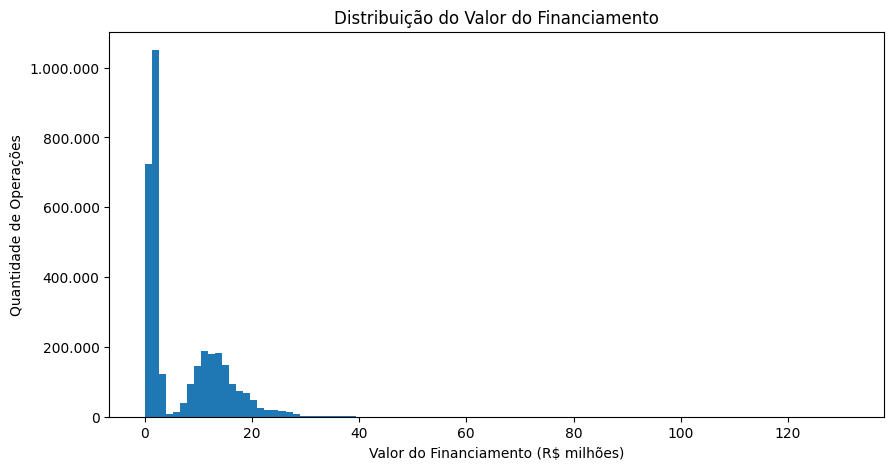

In [19]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plt.figure(figsize=(10,5))

plt.hist(
    df["vlr_financiamento"] / 1_000_000,
    bins=100
)

plt.ylabel("Quantidade de Operações")
plt.xlabel("Valor do Financiamento (R$ milhões)")
plt.title("Distribuição do Valor do Financiamento")

formatter = FuncFormatter(
    lambda x, p: f"{int(x):,}".replace(",", ".")
)

plt.gca().yaxis.set_major_formatter(formatter)

plt.show()

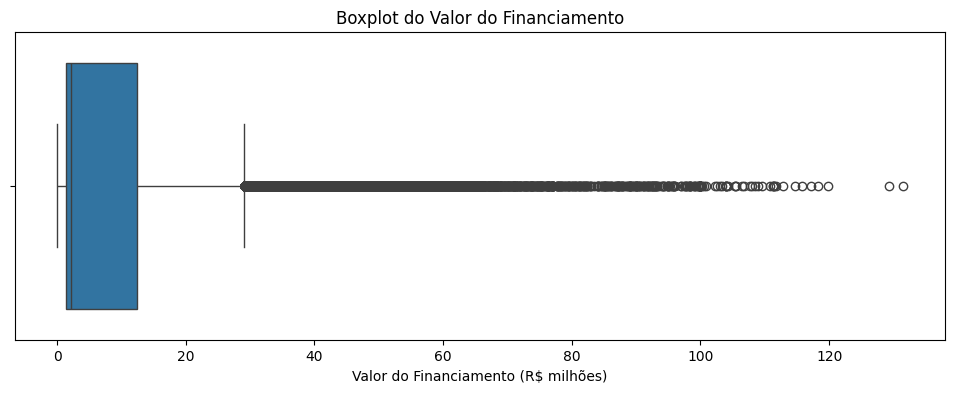

In [24]:
import seaborn as sns

plt.figure(figsize=(12,4))

sns.boxplot(
    x=df["vlr_financiamento"] / 1_000_000
)

plt.xlabel("Valor do Financiamento (R$ milhões)")
plt.title("Boxplot do Valor do Financiamento")

plt.show()

### Análise de valores extremos

O boxplot identificou grande quantidade de observações classificadas como valores extremos segundo a regra do intervalo interquartil (IQR).

Entretanto, a simples classificação estatística como outlier não implica necessariamente erro ou inconsistência nos dados.

Considerando a natureza das operações habitacionais presentes na base, valores elevados podem representar contratos legítimos de maior porte.

Por esse motivo, nenhuma remoção de registros será realizada nesta etapa. A avaliação dos impactos desses valores será considerada posteriormente durante a modelagem.

In [ ]:
(df["vlr_financiamento"] == 0).sum()


np.float64(0.020494607242441475)

In [28]:

(df["vlr_financiamento"] == 0).mean() * 100

np.float64(0.020494607242441475)

### Conclusões sobre a distribuição da variável-alvo

A análise da variável-alvo revelou forte assimetria positiva, com concentração da maior parte das operações em valores relativamente menores e presença de uma longa cauda de financiamentos de maior valor.

A média observada foi significativamente superior à mediana, indicando influência de operações com valores elevados.

Os gráficos evidenciaram a existência de valores extremos sob a ótica estatística. Entretanto, devido à natureza do domínio analisado, esses registros não serão considerados automaticamente inconsistentes.

Também foram identificadas 674 operações com valor igual a zero, representando aproximadamente 0,02% da base, percentual considerado pouco representativo neste estágio da análise.

Os resultados sugerem que a variável apresenta distribuição não normal e elevada dispersão, características que deverão ser consideradas durante a modelagem.

## 3.6 Relação entre renda familiar e valor financiado

A renda familiar representa uma das principais variáveis econômicas disponíveis na base e potencialmente uma das mais relevantes para explicar o valor financiado.

Espera-se que famílias com maior capacidade financeira tenham acesso a operações de maior valor, embora outros fatores também possam influenciar essa relação, como localização, programa habitacional, subsídios e características do imóvel.

Nesta seção serão avaliados:

- distribuição da renda familiar;
- presença de valores extremos;
- relação entre renda familiar e valor financiado;
- evidências iniciais de capacidade explicativa da variável.

Os resultados obtidos poderão contribuir para a seleção das variáveis utilizadas nos modelos de regressão.

In [30]:
df["vlr_renda_familiar"] = (
    df["vlr_renda_familiar"]
    .astype(str)
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
    .astype(float)
)

df["vlr_renda_familiar"].describe()

count    3.288670e+06
mean     2.881654e+05
std      3.217768e+05
min      0.000000e+00
25%      3.920000e+04
50%      2.361075e+05
75%      4.067310e+05
max      4.757644e+07
Name: vlr_renda_familiar, dtype: float64

In [31]:
df["vlr_renda_familiar"].quantile(
    [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
)

0.01      16335.00
0.05      20000.00
0.25      39200.00
0.50     236107.50
0.75     406731.00
0.95     773681.00
0.99    1199814.93
Name: vlr_renda_familiar, dtype: float64

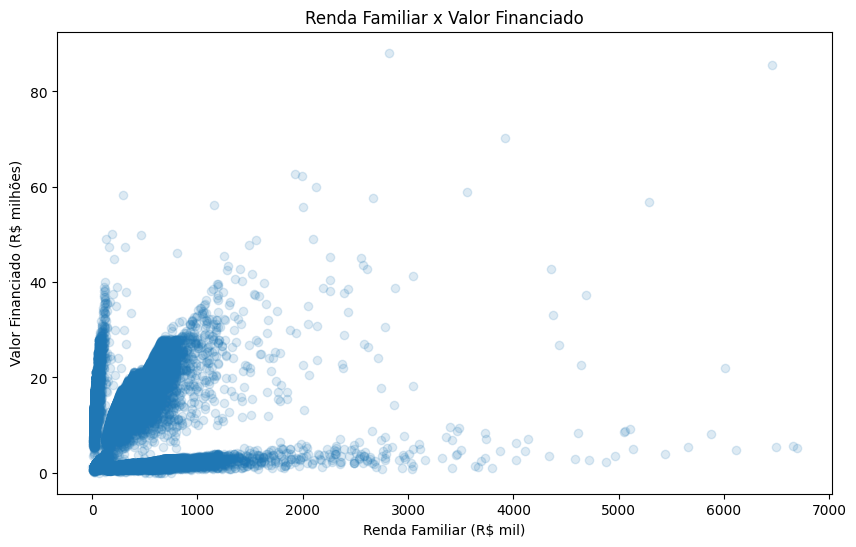

In [36]:
amostra = df.sample(
    n=50000,
    random_state=42
)

plt.figure(figsize=(10,6))

plt.scatter(
    amostra["vlr_renda_familiar"] / 1000,
    amostra["vlr_financiamento"] / 1_000_000,
    alpha=0.15
)

plt.xlabel("Renda Familiar (R$ mil)")
plt.ylabel("Valor Financiado (R$ milhões)")
plt.title("Renda Familiar x Valor Financiado")

plt.show()

### 3.6.1 Relação entre renda familiar e valor financiado

O gráfico de dispersão permite visualizar como o valor financiado se comporta em relação à renda familiar declarada.

Em geral, observa-se uma tendência positiva entre as variáveis, indicando que operações associadas a rendas mais elevadas tendem a apresentar financiamentos de maior valor.

Entretanto, a dispersão observada sugere que a renda familiar não é o único fator determinante do valor financiado, indicando que outras características da operação também exercem influência relevante.